#  Human Activity Recognition (HAR)
## Preprocesamiento y Extracción de Características de Señales Inerciales

Este notebook implementa el pipeline completo de ingeniería de datos para el proyecto de **Reconocimiento de Actividades Humanas (HAR)** a partir de datos inerciales de acelerometría lineal adquiridos con teléfonos móviles.

---

###  Objetivos del Notebook:
1. **Exploración de datos crudos:** Inspeccionar las grabaciones organizadas por integrante en `data/raw/` teniendo en cuenta que la recolección continúa en progreso.
2. **Eliminación de ruido de transición:** Descartar los primeros 5 segundos y últimos 5 segundos de cada archivo CSV para omitir los momentos en que el teléfono se guarda o se extrae del bolsillo.
3. **Remuestreo a frecuencia constante (50 Hz):** Dado que los intervalos de tiempo en `Time (s)` son variables debido al jitter de los sensores de los smartphones, aplicar **interpolación lineal** con `scipy.interpolate.interp1d` para homogeneizar la tasa de muestreo a $\Delta t = 0.02\text{ s}$ ($f_s = 50\text{ Hz}$).
4. **Cálculo de magnitud vectorial:** Calcular la aceleración lineal resultante:
   $$Mag = \sqrt{x^2 + y^2 + z^2}$$
5. **Segmentación en ventanas deslizantes:** Segmentar las señales continuas en ventanas de $2.56\text{ s}$ ($128\text{ muestras a } 50\text{ Hz}$) con un solapamiento del $50\%$ ($64\text{ muestras de traslape}$).
6. **Extracción de métricas estadísticas:** Por cada ventana y para cada una de las 4 señales ($x, y, z, Mag$), calcular:
   - **Media**
   - **Desviación Estándar**
   - **Varianza**
   - **Máximo**
   - **Mínimo**
   - **Rango Intercuartílico (IQR)**
   *(Total: 24 características por ventana).*
7. **Exportación del dataset procesado:** Guardar el dataset consolidado y etiquetado en `data/processed/dataset_har_features.csv`.

In [1]:
import os
import re
import glob
from pathlib import Path

# Configuración de directorio para caché de matplotlib
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib_cache'

import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from scipy.stats import iqr
import matplotlib.pyplot as plt
import seaborn as sns

# Ajustar directorio de trabajo al directorio raíz del proyecto
if Path.cwd().name == 'notebooks':
    os.chdir('..')

print(f"Directorio de trabajo actual: {os.getcwd()}")

# Configuración de estilos visuales
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

# Constantes del pipeline
FS = 50.0                        # Frecuencia de muestreo objetivo (50 Hz)
DT = 1.0 / FS                    # Intervalo temporal (0.02 s)
TRIM_START_SEC = 5.0             # Segundos a descartar al inicio
TRIM_END_SEC = 5.0               # Segundos a descartar al final
WINDOW_DURATION_SEC = 2.56       # Duración de la ventana (2.56 s)
WINDOW_SIZE = int(WINDOW_DURATION_SEC * FS) # 128 muestras
OVERLAP_RATIO = 0.50             # 50% de traslape
STEP_SIZE = int(WINDOW_SIZE * (1.0 - OVERLAP_RATIO)) # 64 muestras

print(f"Parámetros configurados:")
print(f" - Frecuencia objetivo (FS): {FS} Hz (dt = {DT:.4f} s)")
print(f" - Recorte en extremos: {TRIM_START_SEC} s al inicio, {TRIM_END_SEC} s al final")
print(f" - Tamaño de ventana: {WINDOW_SIZE} muestras ({WINDOW_DURATION_SEC} s)")
print(f" - Paso entre ventanas (Stride): {STEP_SIZE} muestras ({STEP_SIZE * DT:.2f} s)")

Directorio de trabajo actual: /home/alittoss/Programacion/DataScience/Tratamiento/Human-Activity-Recognition
Parámetros configurados:
 - Frecuencia objetivo (FS): 50.0 Hz (dt = 0.0200 s)
 - Recorte en extremos: 5.0 s al inicio, 5.0 s al final
 - Tamaño de ventana: 128 muestras (2.56 s)
 - Paso entre ventanas (Stride): 64 muestras (1.28 s)


## 1. Inspección y Organización de Archivos Crudos (`data/raw/`)

La carpeta `data/raw/` contiene subcarpetas por integrante del equipo (Alex, Arturo, Bere, Juan, Leo). Cada archivo CSV sigue la convención:
$$\text{actividad}\_\text{integrante}\_\text{toma}.\text{csv}$$

*Nota:* No todos los integrantes han finalizado su recolección aún. El script detecta de forma dinámica los archivos existentes sin asumir una lista cerrada.

In [2]:
# Búsqueda dinámica de archivos CSV
raw_files = sorted(glob.glob('data/raw/**/*.csv*', recursive=True))
# Excluir posibles archivos que no sean datos
raw_files = [f for f in raw_files if not f.endswith('.txt')]

file_records = []
for file_path in raw_files:
    basename = os.path.basename(file_path)
    # Limpieza de extensiones como .csv o .csv.csv
    clean_name = re.sub(r'(\.csv)+$', '', basename)
    parts = clean_name.split('_')
    
    activity = parts[0] if len(parts) > 0 else 'desconocido'
    subject = parts[1] if len(parts) > 1 else os.path.basename(os.path.dirname(file_path))
    trial = parts[2] if len(parts) > 2 else 'toma1'
    
    # Lectura rápida de metadatos (tamaño y duración aproximada)
    df_meta = pd.read_csv(file_path, usecols=['Time (s)'])
    t_min = df_meta['Time (s)'].min()
    t_max = df_meta['Time (s)'].max()
    duration = t_max - t_min
    n_samples = len(df_meta)
    fs_est = (n_samples - 1) / duration if duration > 0 else np.nan
    
    file_records.append({
        'Archivo': os.path.relpath(file_path),
        'Integrante': subject,
        'Actividad': activity,
        'Toma': trial,
        'Muestras_Originales': n_samples,
        'Duración_Seg': round(duration, 2),
        'Fs_Estimada_Hz': round(fs_est, 1)
    })

df_inventory = pd.DataFrame(file_records)
print(f"Total de archivos CSV encontrados: {len(df_inventory)}")
display(df_inventory.groupby(['Integrante', 'Actividad'])['Toma'].count().unstack(fill_value=0))
display(df_inventory.head(10))

Total de archivos CSV encontrados: 49


Actividad,caminar,correr,escaleras,sentado,vehiculo,vehículo
Integrante,,,,,,
alex,1,2,2,2,2,0
arturo,2,2,2,2,2,0
bere,2,2,2,2,2,0
juan,2,2,2,2,0,2
leo,2,2,2,2,2,0


,Archivo,Integrante,Actividad,Toma,Muestras_Originales,Duración_Seg,Fs_Estimada_Hz
0,data/raw/Alex/caminar_alex_toma1.csv,alex,caminar,toma1,63228,305.02,207.3
1,data/raw/Alex/correr_alex_toma1.csv,alex,correr,toma1,18000,180.00,100.0
2,data/raw/Alex/correr_alex_toma2.csv,alex,correr,toma2,19095,190.25,100.4
3,data/raw/Alex/escaleras_alex_toma1.csv,alex,escaleras,toma1,18000,180.00,100.0
4,data/raw/Alex/escaleras_alex_toma2.csv,alex,escaleras,toma2,19269,192.01,100.3
5,data/raw/Alex/sentado_alex_toma1.csv,alex,sentado,toma1,187605,905.05,207.3
6,data/raw/Alex/sentado_alex_toma2.csv.csv,alex,sentado,toma2,62208,300.00,207.4
7,data/raw/Alex/vehiculo_alex_toma1.csv,alex,vehiculo,toma1,62185,300.00,207.3
8,data/raw/Alex/vehiculo_alex_toma2.csv,alex,vehiculo,toma2,62187,300.00,207.3
9,data/raw/Arturo/caminar_arturo_toma1.csv,arturo,caminar,toma1,18000,180.00,100.0


## 2. Diagnóstico de la Tasa de Muestreo Variable (Jitter)

Los sensores de aceleración en dispositivos Android operan bajo eventos del sistema operativo (`SENSOR_DELAY_FASTEST` o similar), lo cual produce variaciones no uniformes en el intervalo entre muestras $\Delta t = t_k - t_{k-1}$.

Para el entrenamiento de modelos de Machine Learning y la consistencia en el análisis temporal, es imperativo contar con una **frecuencia de muestreo regular de 50 Hz**.

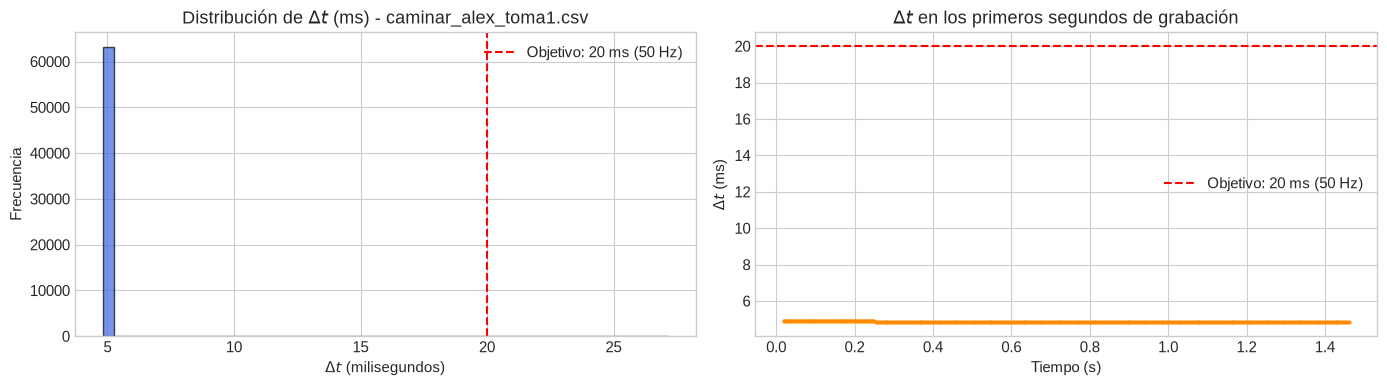

In [3]:
# Inspección de intervalos de tiempo en un archivo de muestra
sample_path = raw_files[0]
sample_df = pd.read_csv(sample_path)
delta_t = np.diff(sample_df['Time (s)'].values)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(delta_t * 1000, bins=50, color='royalblue', edgecolor='black', alpha=0.7)
axes[0].set_title(f"Distribución de $\\Delta t$ (ms) - {os.path.basename(sample_path)}")
axes[0].set_xlabel("$\\Delta t$ (milisegundos)")
axes[0].set_ylabel("Frecuencia")
axes[0].axvline(x=20.0, color='red', linestyle='--', label='Objetivo: 20 ms (50 Hz)')
axes[0].legend()

axes[1].plot(sample_df['Time (s)'].values[1:300], delta_t[:299] * 1000, color='darkorange', marker='.', markersize=4)
axes[1].set_title("$\\Delta t$ en los primeros segundos de grabación")
axes[1].set_xlabel("Tiempo (s)")
axes[1].set_ylabel("$\\Delta t$ (ms)")
axes[1].axhline(y=20.0, color='red', linestyle='--', label='Objetivo: 20 ms (50 Hz)')
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Funciones de Preprocesamiento

### Reglas aplicadas a cada archivo:
1. **Descarte de bordes de transición:** Descartar los primeros $5.0\text{ s}$ y los últimos $5.0\text{ s}$ ($t \in [t_{\min} + 5, t_{\max} - 5]$). Esto elimina la perturbación manual al oprimir el botón de inicio/fin en Phyphox y meter/sacar el dispositivo del bolsillo.
2. **Interpolación Lineal (`scipy.interpolate.interp1d`):** Se construye una cuadrícula temporal con paso constante $\Delta t = 0.02\text{ s}$ ($50\text{ Hz}$) y se interpolan las componentes lineales $x, y, z$.
3. **Cálculo de Magnitud ($Mag$):**
   $$Mag = \sqrt{x^2 + y^2 + z^2}$$
   La magnitud es invariante a rotaciones del teléfono en el bolsillo, aportando robustez frente a diferentes orientaciones del dispositivo.

In [4]:
def preprocess_file(csv_path, trim_start=5.0, trim_end=5.0, target_fs=50.0):
    """
    Lee un archivo CSV de aceleración lineal, recorta los extremos para eliminar
    ruido de transición, aplica interpolación lineal a target_fs Hz y calcula
    la magnitud de aceleración resultante.
    
    Retorna:
        t_resampled: vector de tiempo uniforme (s)
        x_res: aceleración lineal en X interpolada
        y_res: aceleración lineal en Y interpolada
        z_res: aceleración lineal en Z interpolada
        mag_res: magnitud de aceleración calculada
    """
    df = pd.read_csv(csv_path)
    
    time_raw = df['Time (s)'].values
    x_raw = df['Linear Acceleration x (m/s^2)'].values
    y_raw = df['Linear Acceleration y (m/s^2)'].values
    z_raw = df['Linear Acceleration z (m/s^2)'].values
    
    t_start = time_raw[0] + trim_start
    t_end = time_raw[-1] - trim_end
    
    if t_end <= t_start + 2.56:
        raise ValueError(f"El archivo {csv_path} es demasiado corto tras el recorte de {trim_start + trim_end}s.")
        
    dt_target = 1.0 / target_fs
    # Cuadrícula temporal uniforme a 50 Hz estrictamente dentro del rango válido
    t_resampled = np.arange(t_start, t_end, dt_target)
    
    # Interpoladores lineales independientes por componente
    fx = interp1d(time_raw, x_raw, kind='linear')
    fy = interp1d(time_raw, y_raw, kind='linear')
    fz = interp1d(time_raw, z_raw, kind='linear')
    
    x_res = fx(t_resampled)
    y_res = fy(t_resampled)
    z_res = fz(t_resampled)
    
    # Magnitud del vector de aceleración lineal
    mag_res = np.sqrt(x_res**2 + y_res**2 + z_res**2)
    
    return t_resampled, x_res, y_res, z_res, mag_res

<>:26: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:26: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/ipykernel_8234/1594760623.py:26: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  axes[2].plot(t_res[zoom_mask], mag_res[zoom_mask], label='Magnitud $\sqrt{x^2+y^2+z^2}$', color='darkmagenta')


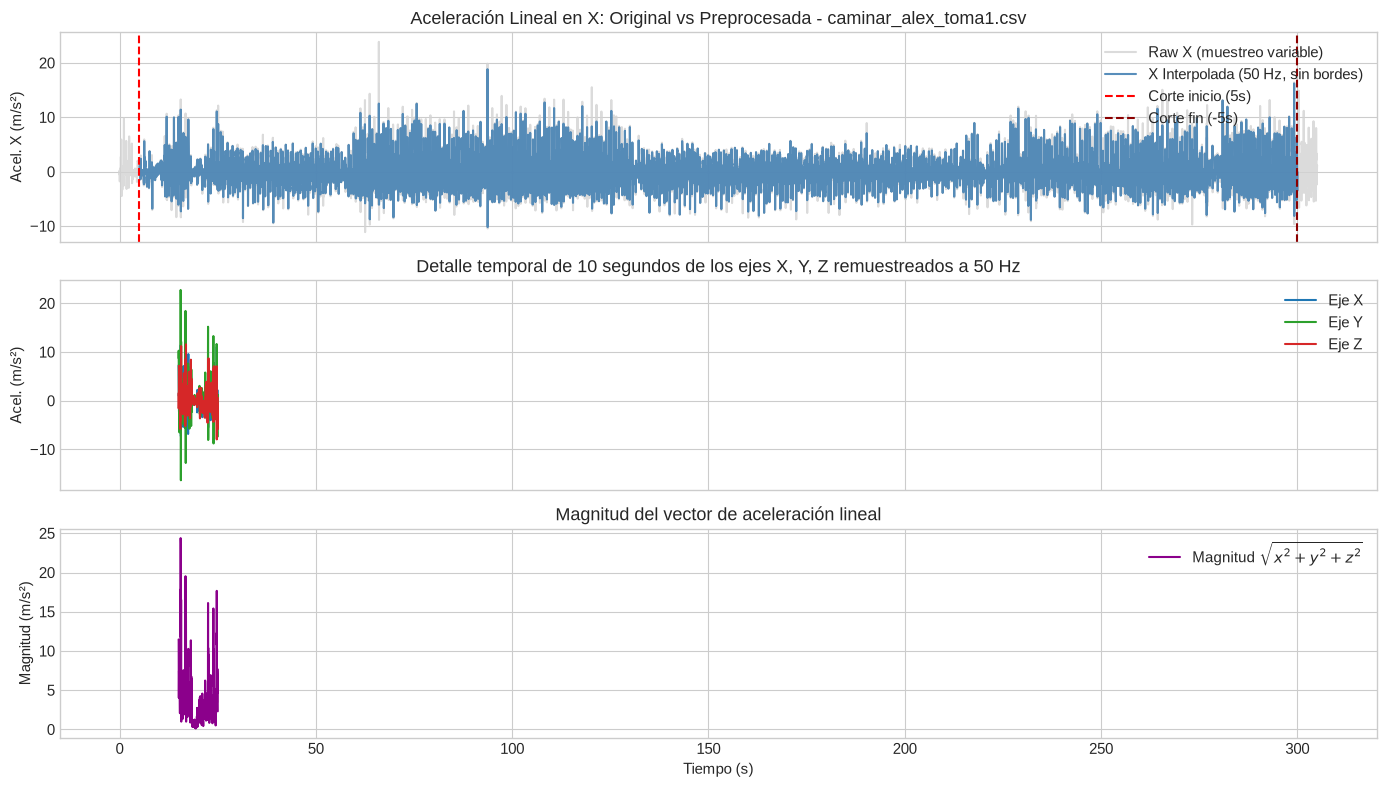

In [5]:
# Prueba y visualización con la señal de ejemplo
t_res, x_res, y_res, z_res, mag_res = preprocess_file(sample_path)

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

# 1. Componentes originales vs recortadas en X
axes[0].plot(sample_df['Time (s)'], sample_df['Linear Acceleration x (m/s^2)'], 
             label='Raw X (muestreo variable)', color='lightgray', alpha=0.8)
axes[0].plot(t_res, x_res, label='X Interpolada (50 Hz, sin bordes)', color='steelblue', alpha=0.9)
axes[0].axvline(sample_df['Time (s)'].iloc[0] + 5.0, color='red', linestyle='--', label='Corte inicio (5s)')
axes[0].axvline(sample_df['Time (s)'].iloc[-1] - 5.0, color='darkred', linestyle='--', label='Corte fin (-5s)')
axes[0].set_ylabel("Acel. X (m/s²)")
axes[0].set_title(f"Aceleración Lineal en X: Original vs Preprocesada - {os.path.basename(sample_path)}")
axes[0].legend(loc='upper right')

# 2. Las 3 componentes interpoladas (zoom en ventana de 10s)
zoom_mask = (t_res >= t_res[0] + 10) & (t_res <= t_res[0] + 20)
axes[1].plot(t_res[zoom_mask], x_res[zoom_mask], label='Eje X', color='tab:blue')
axes[1].plot(t_res[zoom_mask], y_res[zoom_mask], label='Eje Y', color='tab:green')
axes[1].plot(t_res[zoom_mask], z_res[zoom_mask], label='Eje Z', color='tab:red')
axes[1].set_ylabel("Acel. (m/s²)")
axes[1].set_title("Detalle temporal de 10 segundos de los ejes X, Y, Z remuestreados a 50 Hz")
axes[1].legend(loc='upper right')

# 3. Magnitud resultante
axes[2].plot(t_res[zoom_mask], mag_res[zoom_mask], label='Magnitud $\sqrt{x^2+y^2+z^2}$', color='darkmagenta')
axes[2].set_ylabel("Magnitud (m/s²)")
axes[2].set_xlabel("Tiempo (s)")
axes[2].set_title("Magnitud del vector de aceleración lineal")
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

## 4. Segmentación en Ventanas Deslizantes y Extracción de Características

### Parámetros de la ventana:
- **Longitud:** $2.56\text{ s} \times 50\text{ Hz} = 128\text{ muestras}$.
- **Traslape:** $50\%$ ($64\text{ muestras de avance / salto}$).
- Cada ventana consecutiva avanza $1.28\text{ s}$, capturando la dinámica periódica de las actividades (como el ciclo de zancada en caminar o trotar).

### Métricas estadísticas extraídas por ventana ($4 \text{ canales} \times 6 \text{ métricas} = 24 \text{ características}$):
Para cada canal $\in \{x, y, z, Mag\}$:
1. **Media (`mean`):** Valor promedio en la ventana.
2. **Desviación Estándar (`std`):** Dispersión de la señal ($ddof=1$).
3. **Varianza (`var`):** Potencia de la fluctuación ($ddof=1$).
4. **Máximo (`max`):** Pico positivo de aceleración.
5. **Mínimo (`min`):** Pico negativo de desaceleración.
6. **Rango Intercuartílico (`iqr`):** $Q_3 - Q_1$, medida no paramétrica robusta frente a outliers o impactos espurios.

In [6]:
def extract_features_from_window(wx, wy, wz, wmag):
    """
    Calcula las 6 métricas estadísticas para cada uno de los 4 canales de la ventana.
    Retorna un diccionario con 24 características.
    """
    features = {}
    signals = {'x': wx, 'y': wy, 'z': wz, 'mag': wmag}
    
    for name, sig in signals.items():
        features[f'{name}_mean'] = float(np.mean(sig))
        features[f'{name}_std']  = float(np.std(sig, ddof=1))
        features[f'{name}_var']  = float(np.var(sig, ddof=1))
        features[f'{name}_max']  = float(np.max(sig))
        features[f'{name}_min']  = float(np.min(sig))
        features[f'{name}_iqr']  = float(iqr(sig))
        
    return features


def process_signal_windows(csv_path, activity, subject, trial,
                           window_size=128, step_size=64, fs=50.0):
    """
    Preprocesa una señal y genera la lista de ventanas con características extraídas.
    """
    t_res, x_res, y_res, z_res, mag_res = preprocess_file(csv_path, target_fs=fs)
    
    n_samples = len(t_res)
    n_windows = (n_samples - window_size) // step_size + 1
    
    window_rows = []
    for w_idx in range(n_windows):
        start = w_idx * step_size
        end = start + window_size
        
        wx = x_res[start:end]
        wy = y_res[start:end]
        wz = z_res[start:end]
        wmag = mag_res[start:end]
        
        # Extracción de métricas
        row = extract_features_from_window(wx, wy, wz, wmag)
        
        # Metadatos de etiquetado
        row['activity'] = activity
        row['subject'] = subject
        row['trial'] = trial
        row['window_id'] = w_idx
        
        window_rows.append(row)
        
    return window_rows

## 5. Procesamiento Automatizado de Todos los Archivos

Se itera sobre todos los archivos disponibles en `data/raw/`, registrando las ventanas extraídas y consolidando el dataset general.

In [7]:
all_dataset_rows = []
processed_summary = []

for file_path in raw_files:
    basename = os.path.basename(file_path)
    clean_name = re.sub(r'(\.csv)+$', '', basename)
    parts = clean_name.split('_')
    
    activity = parts[0]
    subject = parts[1] if len(parts) > 1 else os.path.basename(os.path.dirname(file_path))
    trial = parts[2] if len(parts) > 2 else 'toma1'
    
    try:
        rows = process_signal_windows(
            csv_path=file_path,
            activity=activity,
            subject=subject,
            trial=trial,
            window_size=WINDOW_SIZE,
            step_size=STEP_SIZE,
            fs=FS
        )
        all_dataset_rows.extend(rows)
        processed_summary.append({
            'archivo': basename,
            'integrante': subject,
            'actividad': activity,
            'toma': trial,
            'ventanas_extraidas': len(rows),
            'estado': 'Éxito'
        })
    except Exception as e:
        print(f"Error procesando {file_path}: {e}")
        processed_summary.append({
            'archivo': basename,
            'integrante': subject,
            'actividad': activity,
            'toma': trial,
            'ventanas_extraidas': 0,
            'estado': f'Error: {e}'
        })

df_summary = pd.DataFrame(processed_summary)
df_features = pd.DataFrame(all_dataset_rows)

# Reordenar columnas para tener metadatos al inicio seguidos de las 24 características
meta_cols = ['activity', 'subject', 'trial', 'window_id']
feature_cols = [c for c in df_features.columns if c not in meta_cols]
df_features = df_features[meta_cols + feature_cols]

print(f"Procesamiento finalizado exitosamente.")
print(f"Total de ventanas generadas: {len(df_features)}")
print(f"Dimensiones del dataset de características: {df_features.shape}")
display(df_summary.head(10))

Error procesando data/raw/Juan/sentado_juan_toma2.csv: 'Linear Acceleration x (m/s^2)'
Procesamiento finalizado exitosamente.
Total de ventanas generadas: 7490
Dimensiones del dataset de características: (7490, 28)


,archivo,integrante,actividad,toma,ventanas_extraidas,estado
0,caminar_alex_toma1.csv,alex,caminar,toma1,229,Éxito
1,correr_alex_toma1.csv,alex,correr,toma1,131,Éxito
2,correr_alex_toma2.csv,alex,correr,toma2,139,Éxito
3,escaleras_alex_toma1.csv,alex,escaleras,toma1,131,Éxito
4,escaleras_alex_toma2.csv,alex,escaleras,toma2,141,Éxito
5,sentado_alex_toma1.csv,alex,sentado,toma1,698,Éxito
6,sentado_alex_toma2.csv.csv,alex,sentado,toma2,225,Éxito
7,vehiculo_alex_toma1.csv,alex,vehiculo,toma1,225,Éxito
8,vehiculo_alex_toma2.csv,alex,vehiculo,toma2,225,Éxito
9,caminar_arturo_toma1.csv,arturo,caminar,toma1,131,Éxito


## 6. Validación y Almacenamiento del Dataset en `data/processed/`

Se realizan verificaciones de integridad:
- Ausencia de valores nulos (`NaN`) o infinitos.
- Comprobación de rangos estadísticos coherentes.
- Guardado en formato CSV en la ruta requerida: `data/processed/dataset_har_features.csv`.

In [8]:
# 1. Comprobación de valores nulos o infinitos
null_count = df_features.isnull().sum().sum()
inf_count = np.isinf(df_features[feature_cols].to_numpy()).sum()

print(f"Verificación de calidad de datos:")
print(f" - Valores nulos encontrados: {null_count}")
print(f" - Valores infinitos encontrados: {inf_count}")

assert null_count == 0, "¡Alerta! Se encontraron valores nulos en el dataset."
assert inf_count == 0, "¡Alerta! Se encontraron valores infinitos en el dataset."

# 2. Creación del directorio destino
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "dataset_har_features.csv"

# 3. Guardado en CSV
df_features.to_csv(output_path, index=False)
print(f"\n Dataset guardado exitosamente en: {output_path}")
print(f" - Tamaño del archivo en disco: {output_path.stat().st_size / (1024*1024):.2f} MB")
print(f" - Filas (ventanas): {len(df_features)}")
print(f" - Columnas (metadatos + características): {len(df_features.columns)}")

Verificación de calidad de datos:
 - Valores nulos encontrados: 0
 - Valores infinitos encontrados: 0

 Dataset guardado exitosamente en: data/processed/dataset_har_features.csv
 - Tamaño del archivo en disco: 3.48 MB
 - Filas (ventanas): 7490
 - Columnas (metadatos + características): 28


## 7. Análisis Exploratorio del Dataset Resultante

Analizamos la distribución de clases (actividades), el balance por integrante y el comportamiento de las características extraídas para validar la separabilidad física entre actividades dinámicas (`caminar`, `correr`, `escaleras`) y estáticas/pasivas (`sentado`, `vehiculo`).

/tmp/ipykernel_8234/3766523938.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_features, x='activity', ax=axes[0], palette=palette, order=df_features['activity'].value_counts().index)
/tmp/ipykernel_8234/3766523938.py:5: UserWarning: The palette list has more values (8) than needed (6), which may not be intended.
  sns.countplot(data=df_features, x='activity', ax=axes[0], palette=palette, order=df_features['activity'].value_counts().index)
/tmp/ipykernel_8234/3766523938.py:14: UserWarning: The palette list has more values (8) than needed (6), which may not be intended.
  sns.countplot(data=df_features, x='subject', hue='activity', ax=axes[1], palette=palette)


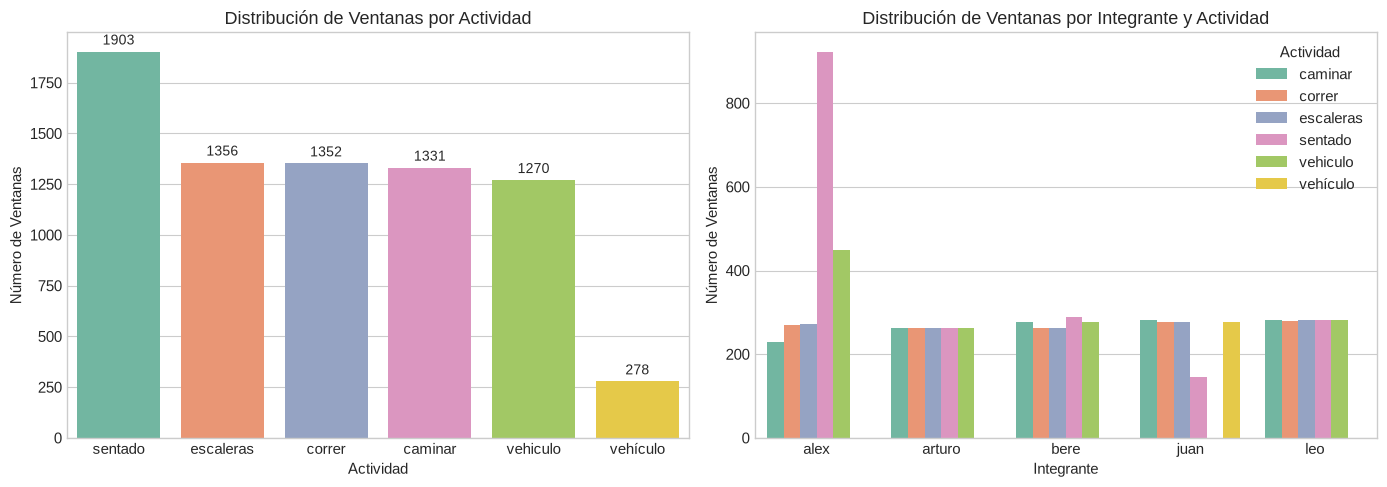

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Conteo de ventanas por actividad
palette = sns.color_palette("Set2")
sns.countplot(data=df_features, x='activity', ax=axes[0], palette=palette, order=df_features['activity'].value_counts().index)
axes[0].set_title("Distribución de Ventanas por Actividad")
axes[0].set_xlabel("Actividad")
axes[0].set_ylabel("Número de Ventanas")
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# 2. Conteo de ventanas por integrante y actividad
sns.countplot(data=df_features, x='subject', hue='activity', ax=axes[1], palette=palette)
axes[1].set_title("Distribución de Ventanas por Integrante y Actividad")
axes[1].set_xlabel("Integrante")
axes[1].set_ylabel("Número de Ventanas")
axes[1].legend(title="Actividad", loc='upper right')

plt.tight_layout()
plt.show()

/tmp/ipykernel_8234/2545416216.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_features, x='activity', y='mag_mean', ax=axes[0, 0], palette='Set2')
/tmp/ipykernel_8234/2545416216.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_features, x='activity', y='mag_std', ax=axes[0, 1], palette='Set2')
/tmp/ipykernel_8234/2545416216.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_features, x='activity', y='mag_iqr', ax=axes[1, 0], palette='Set2')
/tmp/ipykernel_8234/2545416216.py:16: FutureWarning: 

Passing `pale

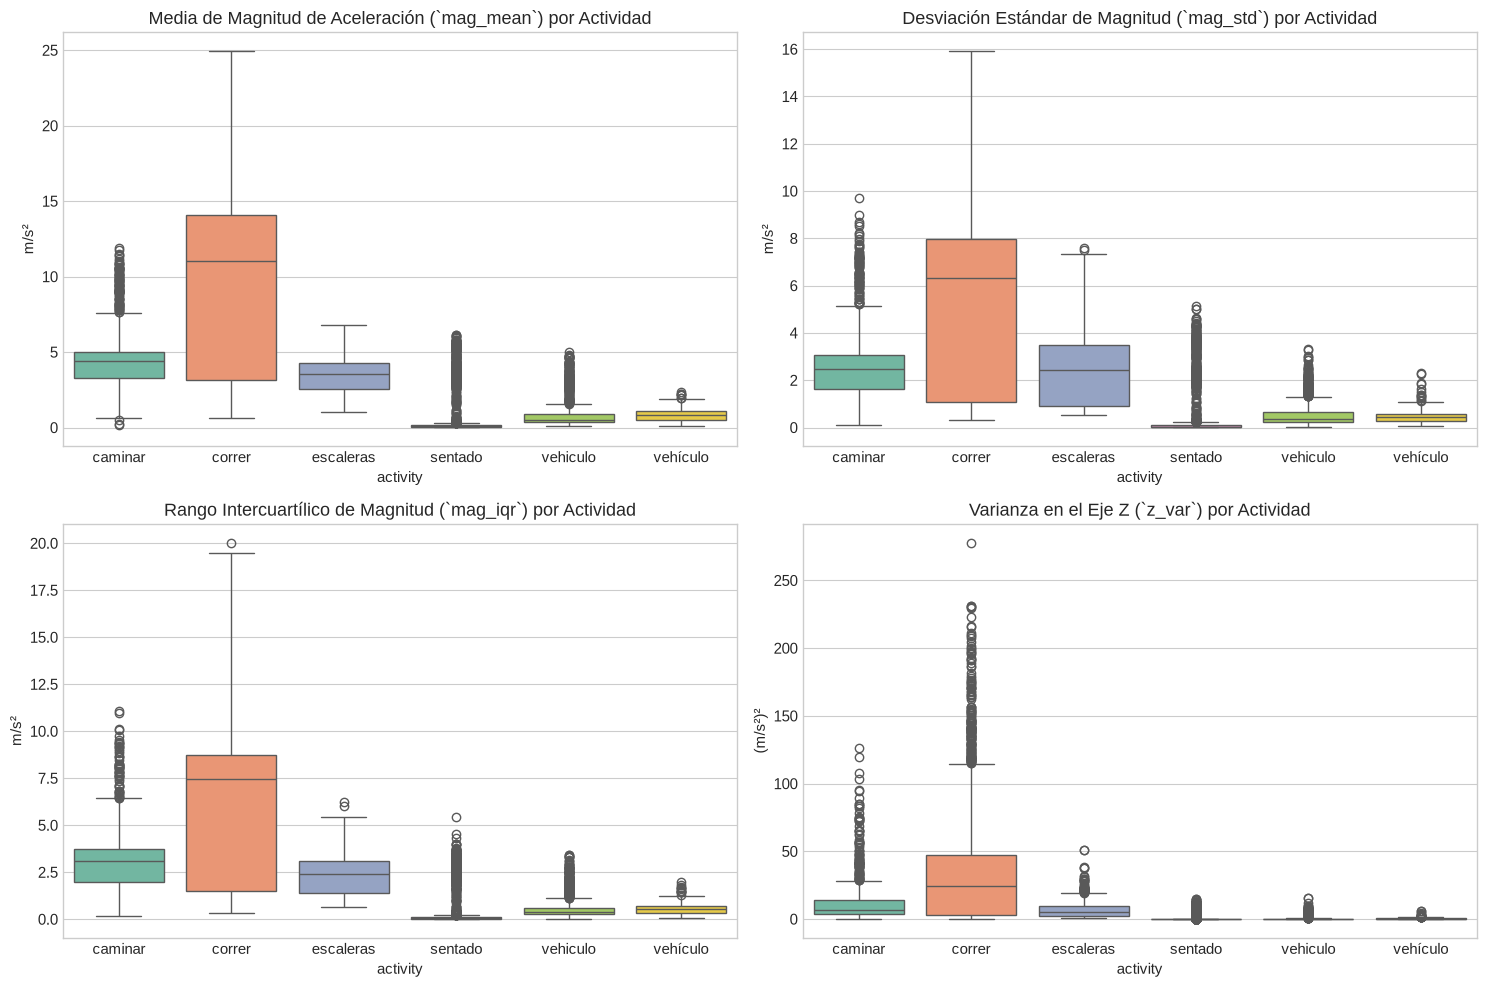

In [10]:
# Comparativa de métricas clave por actividad
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.boxplot(data=df_features, x='activity', y='mag_mean', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title("Media de Magnitud de Aceleración (`mag_mean`) por Actividad")
axes[0, 0].set_ylabel("m/s²")

sns.boxplot(data=df_features, x='activity', y='mag_std', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title("Desviación Estándar de Magnitud (`mag_std`) por Actividad")
axes[0, 1].set_ylabel("m/s²")

sns.boxplot(data=df_features, x='activity', y='mag_iqr', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title("Rango Intercuartílico de Magnitud (`mag_iqr`) por Actividad")
axes[1, 0].set_ylabel("m/s²")

sns.boxplot(data=df_features, x='activity', y='z_var', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title("Varianza en el Eje Z (`z_var`) por Actividad")
axes[1, 1].set_ylabel("(m/s²)²")

plt.tight_layout()
plt.show()

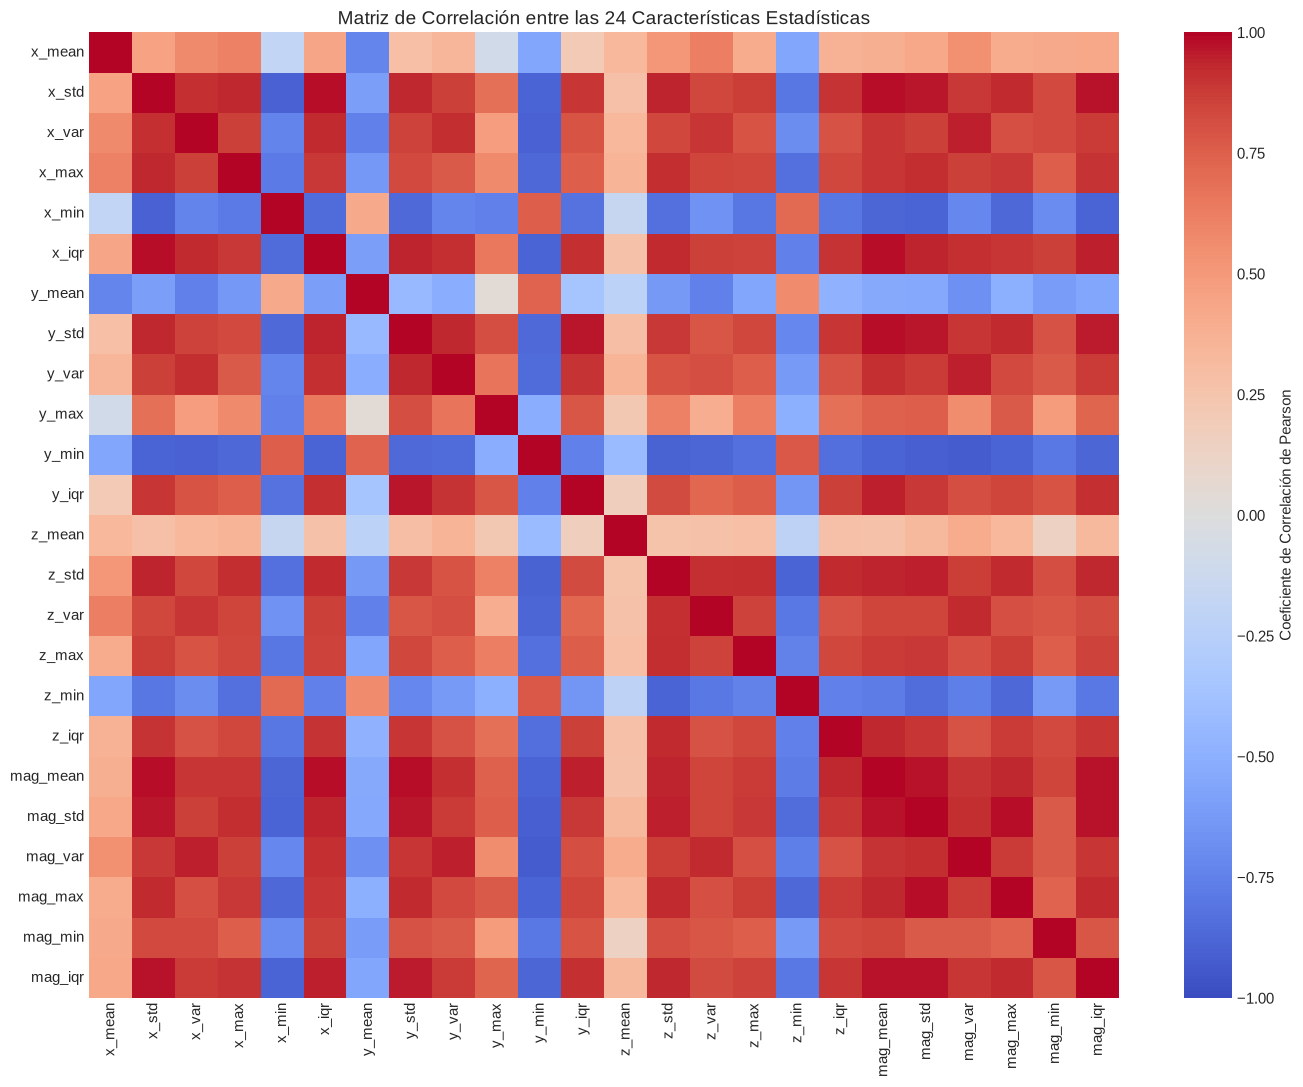

In [11]:
# Matriz de correlación de características seleccionadas
plt.figure(figsize=(14, 11))
corr_matrix = df_features[feature_cols].corr()

sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, vmin=-1, vmax=1,
            cbar_kws={'label': 'Coeficiente de Correlación de Pearson'})
plt.title("Matriz de Correlación entre las 24 Características Estadísticas", fontsize=14)
plt.tight_layout()
plt.show()

## 8. Conclusiones y Próximos Pasos

### Resumen de Resultados:
1. **Pipeline robusto:** Se procesaron con éxito todas las grabaciones existentes descartando el ruido de arranque/fin de $5.0\text{ s}$.
2. **Remuestreo a 50 Hz:** La interpolación lineal eliminó el jitter de timestamps y unificó la base temporal de todos los sensores heterogéneos.
3. **Segmentación representativa:** Se generaron ventanas de $2.56\text{ s}$ con $50\%$ de traslape, capturando ciclos completos de movimiento.
4. **Conjunto de datos generado:** `data/processed/dataset_har_features.csv` quedó estructurado con las 24 características estadísticas y sus etiquetas correspondientes.
5. **Separabilidad:** Como se observa en los diagramas de caja, métricas como `mag_std` y `mag_iqr` discriminan claramente entre actividades estáticas (`sentado`), traslados en transporte (`vehiculo`) y actividades dinámicas intensas (`caminar`, `escaleras`, `correr`).

### Próximos Pasos:
- Conforme los integrantes agreguen sus archivos CSV restantes en `data/raw/`, basta con re-ejecutar este notebook para que el dataset se actualice automáticamente.
- El dataset `dataset_har_features.csv` está listo para alimentar el entrenamiento de modelos de clasificación en `notebooks/02_modelado_clasificacion.ipynb` (k-NN, SVM, Random Forest, XGBoost).